# Obstacle Mask Generation

This notebook loads an elevation sample and markers, then generates an obstacle mask using randomized superellipses. The obstacle mask uses **0** for valid path cells and **1** for forbidden cells.

In [ ]:
from pathlib import Path
import sys

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from passage.generate import generate_sample, find_path, _resolve_solver_config

## Configuration

In [9]:
# Sample generation settings
RESOLUTION = 2048  # 64, 128, 256, 512, 1024, 2048, 4096
SAMPLE_INDEX = 0
DISABLE_IMAGES = True
OVERRIDE_EXISTING = True

# Paths
OUTPUTS_DIR = ROOT / "outputs" / "obstacles"
TILES_DIR = ROOT / "outputs" / "download" / "tiles"
CALIBRATE_PATH = ROOT / "outputs" / "calibrate" / "calibrate.json"
CONFIG_PATH = ROOT / "config" / "config.yaml"

with open(CONFIG_PATH) as f:
    config = yaml.safe_load(f) or {}

# read obstacles config
obstacles_cfg = config.get("obstacles", {})
OBSTACLE_RATIO_MAX = float(obstacles_cfg.get("ratio_max", 0.2))
OBSTACLE_SIZE_MIN_RATIO = float(obstacles_cfg.get("size_min_ratio", 0.05))
OBSTACLE_SIZE_MAX_RATIO = float(obstacles_cfg.get("size_max_ratio", 0.20))

# generation tuning
GENERATION_CFG = obstacles_cfg.get("generation", {})

COST_MODEL = (
    config.get("solver", {}).get("grid", {}).get("cost_model")
    or config.get("solver", {}).get("networkx", {}).get("cost_model")
    or config.get("solver", {}).get("pathfinding", {}).get("cost_model")
    or "elevation"
)

# Solver defaults for sample generation read from config
GEN_SOLVER_CONFIG = _resolve_solver_config(config.get("solver", {}))
GEN_SOLVER_CONFIG.setdefault("name", "grid:astar")
GEN_SOLVER_CONFIG.setdefault("diagonal_movement", "always")
GEN_SOLVER_CONFIG.setdefault("weight", 30.0)
GEN_SOLVER_CONFIG.setdefault("cost_model", COST_MODEL)
GEN_SOLVER_CONFIG.setdefault("heuristic", "euclidean")

'euclidean'

## Load or Generate Sample

In [10]:
# Validate required inputs
if not CALIBRATE_PATH.exists():
    raise FileNotFoundError(f"Calibration file not found: {CALIBRATE_PATH}. Run 'passage calibrate' first.")
if not TILES_DIR.exists():
    raise FileNotFoundError(f"Tiles directory not found: {TILES_DIR}. Run 'passage download' first.")

# Load calibration data
with open(CALIBRATE_PATH) as f:
    calibration = json.load(f)
global_min = float(calibration["global_min"])
global_max = float(calibration["global_max"])
tile_stats_df = pd.DataFrame(calibration["tile_stats"])

tensor_path = OUTPUTS_DIR / str(RESOLUTION) / "tensors" / f"{SAMPLE_INDEX:010d}.npy"
metadata_path = OUTPUTS_DIR / str(RESOLUTION) / "metadata" / f"{SAMPLE_INDEX:010d}.yaml"

if OVERRIDE_EXISTING or not tensor_path.exists() or not metadata_path.exists():
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    args = (
        SAMPLE_INDEX,
        TILES_DIR,
        OUTPUTS_DIR,
        RESOLUTION,
        tile_stats_df,
        global_min,
        global_max,
        DISABLE_IMAGES,
        GEN_SOLVER_CONFIG,
    )
    index, success, message, duration = generate_sample(args)
    print(f"Generate sample: success={success}, message='{message}', duration={duration:.2f}s")
    if not success:
        raise RuntimeError("Sample generation failed. Try a different resolution or re-run calibration.")
else:
    print(f"Using existing tensor: {tensor_path}")

tensor = np.load(tensor_path)
elevation_norm = tensor[:, :, 0]
marker_channel = tensor[:, :, 1]
elevation_raw = elevation_norm * (global_max - global_min) + global_min

print(f"Loaded tensor shape: {tensor.shape}")

2026-01-15 21:45:50.300 | DEBUG    | passage.generate:wrapper:268 - ### ENTER generate_sample()
2026-01-15 21:45:50.303 | DEBUG    | passage.generate:generate_sample:1276 - Loading full grid for center=(41,-121) half_tiles=1
2026-01-15 21:45:50.303 | DEBUG    | passage.generate:wrapper:268 - ### ENTER load_tile_grid()
2026-01-15 21:45:50.304 | DEBUG    | passage.generate:wrapper:268 - ### ENTER load_tile()
2026-01-15 21:45:50.305 | DEBUG    | passage.generate:load_tile:950 - Using tile file: /shared/home/geoffrey.delhomme.e/projects/PASSAGE/passage/outputs/download/tiles/ALPSMLC30_N042W122_DSM.tif


2026-01-15 21:45:50.650 | DEBUG    | passage.generate:wrapper:275 - ### EXIT load_tile() duration=0.3461s
2026-01-15 21:45:50.651 | DEBUG    | passage.generate:wrapper:268 - ### ENTER load_tile()
2026-01-15 21:45:50.653 | DEBUG    | passage.generate:load_tile:950 - Using tile file: /shared/home/geoffrey.delhomme.e/projects/PASSAGE/passage/outputs/download/tiles/ALPSMLC30_N042W121_DSM.tif
2026-01-15 21:45:51.018 | DEBUG    | passage.generate:wrapper:275 - ### EXIT load_tile() duration=0.3669s
2026-01-15 21:45:51.019 | DEBUG    | passage.generate:wrapper:268 - ### ENTER load_tile()
2026-01-15 21:45:51.021 | DEBUG    | passage.generate:load_tile:950 - Using tile file: /shared/home/geoffrey.delhomme.e/projects/PASSAGE/passage/outputs/download/tiles/ALPSMLC30_N042W120_DSM.tif
2026-01-15 21:45:51.351 | DEBUG    | passage.generate:wrapper:275 - ### EXIT load_tile() duration=0.3312s
2026-01-15 21:45:51.414 | DEBUG    | passage.generate:wrapper:268 - ### ENTER load_tile()
2026-01-15 21:45:51.41

Generate sample: success=True, message='Generated sample 0', duration=14.47s
Loaded tensor shape: (2048, 2048, 2)


## Obstacle Generation

In [11]:
def generate_obstacles_mask(
    shape,
    ratio_max,
    size_min_ratio,
    size_max_ratio,
    marker_positions=None,
    rng=None,
    max_attempts=None,
    generation_cfg=None,
):
    """Generate an obstacle mask using randomized superellipses.

    Returns (mask, target_ratio).
    - mask: uint8 array with 0 (free) and 1 (obstacle)
    - target_ratio: randomly drawn in [0, ratio_max]

    Simplified behavior: sizes are drawn between `size_min_ratio` and `size_max_ratio` (no
    additional height caps or external exponent configuration). Procedural tuning is driven
    by `generation_cfg` (max_attempts, candidates_per_mask).
    """
    rng = np.random.default_rng() if rng is None else rng
    height, width = shape
    ratio_max = float(max(0.0, ratio_max))

    marker_positions = [] if marker_positions is None else [tuple(map(int, p)) for p in marker_positions]

    gen = generation_cfg if generation_cfg is not None else obstacles_cfg.get("generation", {})
    max_attempts = int(gen.get("max_attempts", 50)) if max_attempts is None else int(max_attempts)
    candidates_per_mask = int(gen.get("candidates_per_mask", 200))

    for _ in range(max_attempts):
        target_ratio = float(rng.uniform(0.0, ratio_max))
        mask = np.zeros((height, width), dtype=np.uint8)

        if target_ratio <= 0.0:
            return mask, target_ratio

        size_min_ratio = float(max(0.0, size_min_ratio))
        size_max_ratio = float(max(size_min_ratio, size_max_ratio))

        min_w = max(1, int(size_min_ratio * width))
        max_w = max(1, int(size_max_ratio * width))
        min_h = max(1, int(size_min_ratio * height))
        max_h = max(1, int(size_max_ratio * height))

        yy, xx = np.mgrid[0:height, 0:width]

        for _ in range(candidates_per_mask):
            w = int(rng.integers(min_w, max_w + 1))
            h = int(rng.integers(min_h, max_h + 1))
            cx = int(rng.integers(0, width))
            cy = int(rng.integers(0, height))
            angle = float(rng.uniform(0.0, 2 * np.pi))
            n = float(rng.uniform(2.0, 4.0))

            x = xx - cx
            y = yy - cy
            cos_a = np.cos(angle)
            sin_a = np.sin(angle)
            xr = x * cos_a + y * sin_a
            yr = -x * sin_a + y * cos_a

            a = max(w / 2.0, 1.0)
            b = max(h / 2.0, 1.0)
            candidate = (np.abs(xr) / a) ** n + (np.abs(yr) / b) ** n <= 1.0

            new_ratio = np.mean(mask | candidate)
            if new_ratio > target_ratio:
                break

            mask = np.logical_or(mask, candidate).astype(np.uint8)

        # ensure no marker is inside mask
        if any(mask[i, j] == 1 for i, j in marker_positions):
            continue

        return mask, target_ratio

    return np.zeros((height, width), dtype=np.uint8), 0.0

In [12]:
marker_positions = np.argwhere(marker_channel > 0)

obstacles_mask, target_ratio = generate_obstacles_mask(
    elevation_raw.shape,
    OBSTACLE_RATIO_MAX,
    OBSTACLE_SIZE_MIN_RATIO,
    OBSTACLE_SIZE_MAX_RATIO,
    marker_positions=marker_positions,
)

tensor_with_obstacles = np.stack([elevation_norm, marker_channel, obstacles_mask], axis=-1)

print(f"Target obstacle ratio: {target_ratio:.3f}")
print(f"Actual obstacle ratio: {obstacles_mask.mean():.3f}")
print(f"Tensor with obstacles shape: {tensor_with_obstacles.shape}")

Target obstacle ratio: 0.054
Actual obstacle ratio: 0.000
Tensor with obstacles shape: (2048, 2048, 3)


## Pathfinding (grid:astar)

In [ ]:
marker_positions = np.argwhere(marker_channel > 0)
if marker_positions.shape[0] < 2:
    raise RuntimeError("Expected at least two markers in marker channel.")

start = tuple(marker_positions[0])
end = tuple(marker_positions[1])

# Resolve solver config from config.yaml (supports common + backend sections)
solver_config = _resolve_solver_config(config.get("solver", {}))
# Ensure sensible defaults
solver_config.setdefault("diagonal_movement", "always")
solver_config.setdefault("weight", 30.0)
solver_config.setdefault("cost_model", COST_MODEL)
solver_config.setdefault("heuristic", "euclidean")

# Penalize obstacle cells heavily to discourage traversal
obstacle_penalty = 1e6
masked_elevation = elevation_raw.copy()
masked_elevation[obstacles_mask == 1] = masked_elevation.max() + obstacle_penalty

path = find_path(masked_elevation, start, end, solver_config)

2026-01-15 21:46:05.150 | DEBUG    | passage.generate:wrapper:268 - ### ENTER find_path()
2026-01-15 21:46:05.151 | DEBUG    | passage.generate:find_path:530 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=100.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(2048, 2048), start=(np.int64(789), np.int64(402)), end=(np.int64(1845), np.int64(159))


2026-01-15 21:46:16.890 | DEBUG    | passage.generate:find_path:547 - Grid solver finished: path_len=1323, solve_time=11.7385s, total=11.7385s
2026-01-15 21:46:16.891 | DEBUG    | passage.generate:wrapper:275 - ### EXIT find_path() duration=11.7399s


Path length: 1323


## Visualization

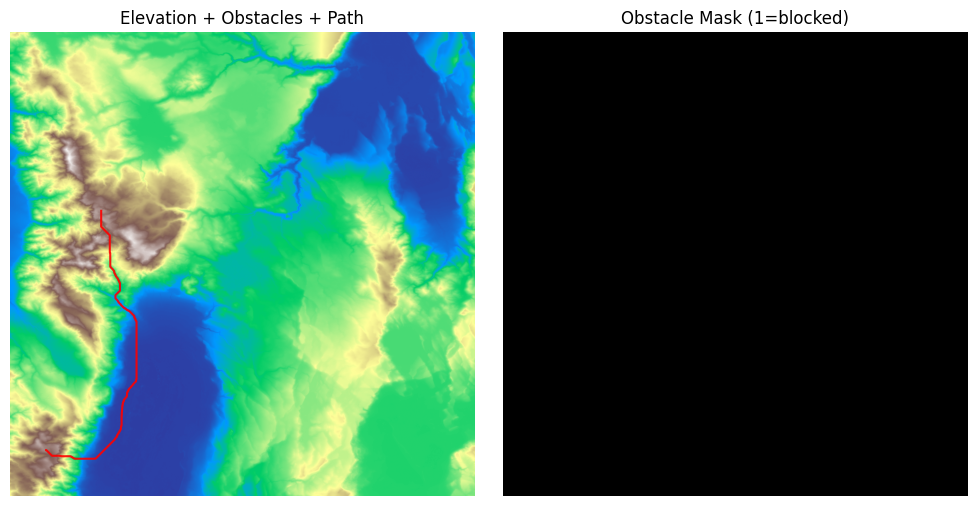

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(elevation_norm, cmap="terrain")
ax[0].imshow(np.ma.masked_where(obstacles_mask == 0, obstacles_mask), cmap="Reds", alpha=0.5)

if path:
    path_arr = np.array(path)
    ax[0].plot(path_arr[:, 1], path_arr[:, 0], "r-", linewidth=1.5, alpha=0.9, label="Path")

ax[0].set_title("Elevation + Obstacles + Path")
ax[0].axis("off")

ax[1].imshow(obstacles_mask, cmap="gray")
ax[1].set_title("Obstacle Mask (1=blocked)")
ax[1].axis("off")

plt.tight_layout()
plt.show()